# 03 · Extensión experimental: tamaño de muestra

Única condición modificada: n = 299, 1 000 y 2 990 pacientes simulados con el mismo proceso generador. Protocolo común: 70/30 estratificado, 30 repeticiones.

## Experimento

In [1]:
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
print("Raíz del proyecto:", RAIZ)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.simulacion import simular
from src.modelos import experimento_tamano

pd.set_option("display.width", 200, "display.max_columns", 30)

inicio = time.time()
res_ext = experimento_tamano(simular, factores=[1, 1000 / 299, 10], n_rep=30)
print(f"Tiempo: {(time.time() - inicio) / 60:.1f} min")

res_ext.to_csv("results/extension_tamano_muestra.csv", index=False)

tabla_ext = (res_ext.groupby(["modelo", "variables", "n"])["MCC"]
             .agg(["mean", "std"]).round(3).unstack("n"))
tabla_ext.to_csv("results/extension_tamano_resumen.csv")
print(tabla_ext.to_string())

Raíz del proyecto: /Users/estebanbejaranocaldas/Documents/maestria_analitica/Trabajo final ML/proyecto_ml_final
  n = 299 listo
  n = 1000 listo
  n = 2990 listo
Tiempo: 1.1 min
                                 mean                  std              
n                                299    1000   2990   299    1000   2990
modelo            variables                                             
Gradient boosting 11 variables  0.280  0.367  0.418  0.085  0.048  0.029
                  2 variables   0.163  0.306  0.312  0.095  0.052  0.029
Naive bayes       11 variables  0.351  0.305  0.273  0.091  0.048  0.030
                  2 variables   0.220  0.268  0.290  0.076  0.049  0.030
Random forests    11 variables  0.378  0.447  0.465  0.087  0.049  0.027
                  2 variables   0.214  0.279  0.269  0.077  0.049  0.030
SVM radial        11 variables  0.258  0.318  0.375  0.087  0.052  0.029
                  2 variables   0.289  0.371  0.385  0.085  0.037  0.026


## Figura

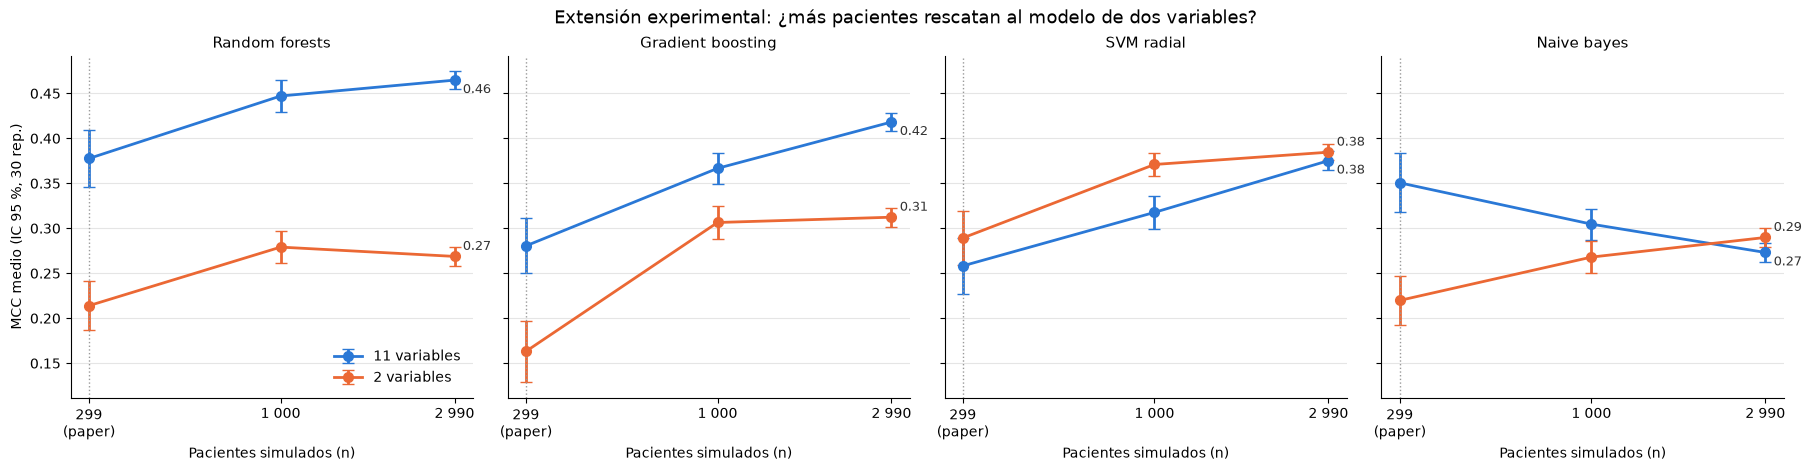

In [2]:
COLORES = {"11 variables": "#2a78d6", "2 variables": "#eb6834"}
modelos = ["Random forests", "Gradient boosting", "SVM radial", "Naive bayes"]
resumen = res_ext.groupby(["modelo", "variables", "n"])["MCC"].agg(["mean", "std", "count"]).reset_index()
resumen["ic95"] = 1.96 * resumen["std"] / np.sqrt(resumen["count"])

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True, constrained_layout=True)
for ax, m in zip(ejes, modelos):
    for conj, color in COLORES.items():
        d = resumen[(resumen.modelo == m) & (resumen.variables == conj)].sort_values("n")
        ax.errorbar(d["n"], d["mean"], yerr=d["ic95"], color=color, lw=2, marker="o", ms=7,
                    capsize=4, label=conj)
        desplazamiento = 7 if conj == "2 variables" else -7
        ax.annotate(f"{d['mean'].iloc[-1]:.2f}", (d["n"].iloc[-1], d["mean"].iloc[-1]),
                    xytext=(6, desplazamiento), textcoords="offset points", va="center",
                    fontsize=9, color="#333")
    ax.axvline(299, color="#999", ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xticks([299, 1000, 2990])
    ax.set_xticklabels(["299\n(paper)", "1 000", "2 990"])
    ax.minorticks_off()
    ax.set_title(m, fontsize=11)
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("Pacientes simulados (n)")
ejes[0].set_ylabel("MCC medio (IC 95 %, 30 rep.)")
ejes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Extensión experimental: ¿más pacientes rescatan al modelo de dos variables?", fontsize=13)
fig.savefig("figures/03_extension_tamano.png", dpi=150, bbox_inches="tight")
plt.show()

## Diagnóstico de Naive Bayes: supuesto de normalidad frente a variables lognormales

In [3]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef
from src.modelos import VARIABLES_CLINICAS

filas = []
for factor in [1, 1000 / 299, 10]:
    datos = simular(factor_n=factor, random_state=42)
    y = datos["DEATH_EVENT"].to_numpy(int)
    for transformacion in ["crudo", "log(CPK) y log(creatinina)"]:
        X = datos[VARIABLES_CLINICAS].astype(float)
        if transformacion != "crudo":
            X[["creatinine_phosphokinase", "serum_creatinine"]] = np.log(X[["creatinine_phosphokinase", "serum_creatinine"]])
        mcc = []
        for rep in range(30):
            X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y, test_size=0.3, stratify=y, random_state=42 + rep)
            mcc.append(matthews_corrcoef(y_te, GaussianNB().fit(X_tr, y_tr).predict(X_te)))
        filas.append({"n": len(datos), "variables": transformacion, "MCC": np.mean(mcc)})

diag_nb = pd.DataFrame(filas).pivot(index="variables", columns="n", values="MCC").round(3)
diag_nb.to_csv("results/diagnostico_naive_bayes_log.csv")
print(diag_nb.to_string())

n                            299    1000   2990
variables                                      
crudo                       0.351  0.305  0.273
log(CPK) y log(creatinina)  0.353  0.357  0.344
